## TRUCS : Comment tracer un Bode en continu

Sans être dépendant de librairies obscure et chères !


In [1]:
clear all; %efface les variables du workspace
close all; % ferme les fenêtre graphique déjà ouvertes
graphics_toolkit ("gnuplot"); %% A exécuter uniquement pour les Notebooks Octave, pas pour Octave ni Matlab ni python


The gnuplot graphics toolkit is not actively maintained and has a number
of limitations that are ulikely to be fixed.  Communication with gnuplot
uses a one-directional pipe and limited information is passed back to the
Octave interpreter so most changes made interactively in the plot window
will not be reflected in the graphics properties managed by Octave.  For
example, if the plot window is closed with a mouse click, Octave will not
be notified and will not update it's internal list of open figure windows.
We recommend using the qt toolkit instead.


#  Solution
Il suffit de calculer G(p=jw) et d'afficher son module et son argument.
L'astuce consiste à utiliser un vecteur f contenant toute les valeurs de fréquences qui nous intéressent (au lieu de remplir un tableau avec un boucle for, ...)

Prenons un exemple que **NE PEUT PAS FAIRE** la boîte à outils "control" (500 euros/étudiant.e.s) de Matlab avec sa fonction "bode" :

Traçons la réponse de $G(p)=\frac{1-e^{\tau.p}}{\tau.p}$,  

  - en échelle linéaire avec les fréquences négatives. 

  - en échelle log log :  le bode classique.


## A-1 -En échelle lin/lin

G =

@(x) (1 - exp (-tau * x)) / tau ./ x

Elapsed time is 0.00331497 seconds.


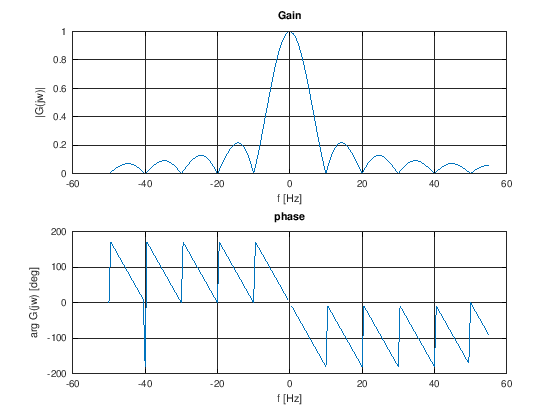

In [2]:
clear all;
%% Définition du G(p)
tau=0.1;
G = @(x) (1-exp(-tau*x))/tau ./ x   % Là,  G est une fonction pas un nombre !

%% Définition de la plage de fréquence et de la résolution du calcul
fmin=-50;
fmax=55;
Df = 0.5 ; % tout les 1/2 Hz

%% UTILISATEURICE NE PAS MODIFIER LA SUITE
f= fmin: Df: fmax;  % vecteur des fréquence [fmin fmin+Df ... fmax]
w = 2*pi*f;         % vecteurs des pulsations 
p = i*w;            % vecteur des valeurs complexe de p(w) = [p(0) p(2.pi.Df) ... p(2. pi.fmax) ] 

%% Calcul des TOUS les G(jw) en quelques ms !
tic 
gains = G(p);  % le vecteur de tous gains complexes [G(O) G(i.2.pi.Df) ... G(i2pi.fmax)]
toc

%% Affichage linéaire
figure(1);
subplot(211); %Fenêtre coupée en 2 rangées de 1 colonnes de graphique, on se met dans la partie 1 (haut)
plot(f, abs(gains));
title("Gain");
xlabel("f [Hz]");
ylabel("|G(jw)|");
grid on;
subplot(212); % même découpage mais on se met dans la partie 2 (Bas)
plot(f, angle(gains)*180/pi);
title("phase");
xlabel("f [Hz]");
ylabel("arg G(jw) [deg]");
grid on;


Et oui !

On décompose G(p) en systèmes simples : $\frac{1-e^{-\tau.p}}{\tau.p} = \underbrace{\frac{1}{\tau}}_{\text{gain}} . \underbrace{\frac{1}{p}}_{\text{intégrateur}} \left(1 - \underbrace{e^{-\tau.p}}_{retard} \right)$

On obtient la division par $\tau$ de la réponse impulsionnelle d'un intégrateur (l'échelon) à laquelle on soustrait le même échelon retardée d'un temps $\tau$ : 

La réponse impulsionnelle est la fonction porte $h(t) = \Pi_{\left[0, \tau\right]}(t)$ qui vaut 1 pour $0<t<\tau$ et 0 ailleurs. 

Ce qui vaut la fonction porte $\Pi_\tau$ de largeur $\tau$ centrée en $0$ retardée de la demi largeur $\frac{\tau}{2}$ :

$\vec{h} = \vec{\Pi_{\left[0, \tau\right]}} = \vec{\Pi_{\tau}}(\bullet-\frac{\tau}{2})$

Comme la réponse impulsionnelle de ce retard est $\delta_{\frac{\tau}{2}}$ , et que passer dans ce système revient à calculer la convolution $\star$ du signal d'entré avec cette impulsion, on a :

$\vec{h} = \vec{\Pi_{\tau}}\star\vec{\delta_{\frac{\tau}{2}}} $

**Il s'agit donc du filtre qui fait la moyenne sur un temps $\tau$ du signal entrant** 

La réponse harmonique de ce système est un sinus cardinal $G(i.2\pi.f) = \underbrace{e^{-i.2\pi.f.\frac{\tau}{2}}}_{\text{retard}}.\frac{\sin(2\pi.f.\frac{\tau}{2})}{2\pi.f.\frac{\tau}{2}}=\underbrace{e^{-i.2\pi.f.\frac{\tau}{2}}}_{\text{de}\frac{\tau}{2}}.\sin\!c(2\pi.f.\frac{\tau}{2})$. 

On retrouve ainsi la transformée de Fourrier de la fonction porte:

$\mathcal{F}\left\{\vec{\Pi_{\tau}}\star\vec{\delta_{\frac{\tau}{2}}}\right\}(\omega) = \underbrace{e^{-i.\omega.\frac{\tau}{2}}}_{\mathcal{F}\{\delta_{\tau/2}\}}.\underbrace{\sin\!c(2\pi.f.\frac{\tau}{2})}_{\mathcal{F}\{\Pi_\tau\}}$


On comprend alors pourquoi le gain s'annule, tout les multiples de 10 Hz :

**La moyenne glissante sur une durée $\tau$ s'annule pour toutes fréquences $\tau$-périodiques : $f_m = m.\frac{1}{\tau}$**

## A-2 - En échelle Log/Log : Bode

Pour le Bode classique, il suffit de :
  - calculer le gain en dB avec 20*log(abs(gains)) (**Attention** avec matlab `log` est $ln$, et `log10` est $Log$
  - utiliser une echelle log en fréquences : en raplaçant `plot` par `semilogx`.

    __plt__>__plt2vv__ at line 500 column 10
    __plt__>__plt2__ at line 247 column 14
    __plt__ at line 112 column 18
    semilogx at line 65 column 10

    __plt__>__plt2vv__ at line 500 column 10
    __plt__>__plt2__ at line 247 column 14
    __plt__ at line 112 column 18
    semilogx at line 65 column 10



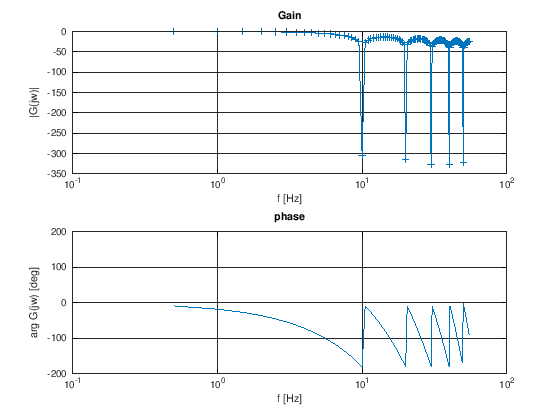

In [3]:
%% Affichage log log : Bode
figure(2);
subplot(211); %Fenêtre coupée en 2 rangées de 1 colonnes de graphique, on se met dans la partie 1 (haut)
semilogx(f, 20*log10(abs(gains)),'-+');
title("Gain");
xlabel("f [Hz]");
ylabel("|G(jw)|");
grid on;
subplot(212); % même découpage mais on se met dans la partie 2 (Bas)
semilogx(f, angle(gains)*180/pi);
title("phase");
xlabel("f [Hz]");
ylabel("arg G(jw) [deg]");
grid on;

Les fréquences négatives et petites posent des problèmes d'échelle log.
c'est à l'utilisateurice de savoir indiquer un `fmin` pas trop délirant.

On voit que la résolution en échelle log, n'est pas constante (points espacés à gauche et denses à droite). On peut corriger cela en recalculant les gains que pour des fréquences positives, et espacées régulièrement sur une échelle musicalle (log)

Cela donne :

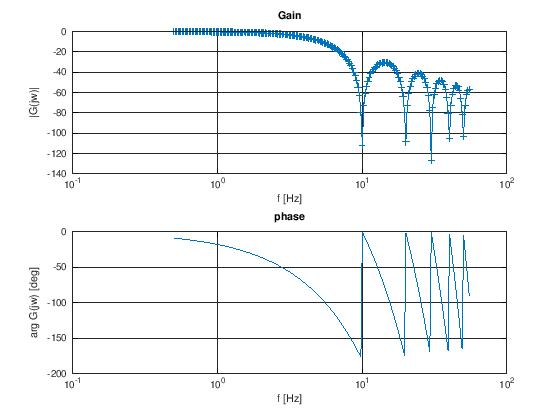

In [4]:
%% calculs en échelle log (musicale)
N = length(f) ;% nombre de points dans l'échelle lde fréquence linéaire
logfmin = log10(max(Df,fmin)); % on prend le log du plus petit f positif non nul de f linéaire
logfmax = log10(fmax);
a = (logfmax-logfmin)/(N-1);
logf = logfmin :  a    : logfmax ;  % on a [log(fmin) a.log(fmin) 2a.log(fmin)... log(fmax) ]
f=10.^logf;        % on a [log(fmin) a.log(fmin) 2a.log(fmin)... log(fmax) ]
w = 2*pi*f;         % vecteurs des pulsations 
p = i*w;            % vecteur des valeurs complexe de p(w) = [p(0) p(2.pi.Df) ... p(2. pi.fmax) ] 
gains = G(p);  % le vecteur de tous gains complexes [G(O) G(i.2.pi.Df) ... G(i2pi.fmax)]


%% Affichage log log : Bode
figure(3);
subplot(211); %Fenêtre coupée en 2 rangées de 1 colonnes de graphique, on se met dans la partie 1 (haut)
semilogx(f, 20*log(abs(gains)),'-+');
title("Gain");
xlabel("f [Hz]");
ylabel("|G(jw)|");
grid on;
subplot(212); % même découpage mais on se met dans la partie 2 (Bas)
semilogx(f, angle(gains)*180/pi);
title("phase");
xlabel("f [Hz]");
ylabel("arg G(jw) [deg]");
grid on;

## B -  Détails techniques : sur la définition de G(p)

Le meilleur outils pour définir une fonction $p \to G(p)$ est d'utiliser une fonction anonyme (Octave, Matlab, Python, ...)  

En Octave/Matlab la fonction anomyme utilise @ (anonymous, ou "at" variable)  est du type 

                @(x) x^2

En python  c'est le terme lambda :

                lambda x : x**2

Mais attention ! 

La fonction est définie avec les variables du moment  et ne s'adapte plus aux changement de paramètre :

In [5]:
clear all;
G = @(x) 1-exp(tau*x)/tau/x   % G est de type fonction ! pas un nombre



G =

@(x) 1 - exp (tau * x) / tau / x



Tout semble bon, mais en fait non. 

L'implémentation est "lazy" : tant que l'on n'as pas utilisé la fonction, elle n'est pas "compilée à la volée" pour être exécutée :

In [6]:
p=0;
G(p)     % erreur car tau n'est pas défini... comment la calculer.


error: 'tau' undefined near line 1, column 1
error: called from
    @<anonymous> at line 1 column 11


Il faut donc que le contexte (les paramètres qui ne sont pas des arguments) soit définit **au moment de la déclaration** :

In [7]:
clear all;
G = @(x) 1-exp(tau*x)/tau/x   % G est de type fonction ! pas un nombre
tau=0.1;
G(0)

G =

@(x) 1 - exp (tau * x) / tau / x

error: 'tau' undefined near line 1, column 1
error: called from
    @<anonymous> at line 1 column 11


ne fionctionne pas mais en revanche

In [8]:
clear all;
tau=0.1;
G = @(x) 1-exp(tau*x)/tau/x   % G est de type fonction ! pas un nombre
G(1)
tau=10;
G(1)

G =

@(x) 1 - exp (tau * x) / tau / x

ans = -10.052
ans = -10.052


Remarquez que c'est la valeur de `tau` **au moment de la définition** qui est utilisée. 

Redéfinir `tau=10` après, ne change pas la première définition.

Si l'on veut une fonction paramétrée il faut mettre un argument à la définition **et** une valeur lors de l'appel :

In [9]:
clear all;
G = @(x,tau) 1-exp(tau*x)/tau/x   % G est de type fonction ! pas un nombre
G(1,0.1)
tau=10;
G(1,0.1)
G(1,tau)
G(1,10)


G =

@(x, tau) 1 - exp (tau * x) / tau / x

ans = -10.052
ans = -10.052
ans = -2201.6
ans = -2201.6


## C - Détails techniques : Vectorisation de G(p) 
La vectorisation consiste à rendre possible l'appel de G(p) avec des arguments p qui ne sont pas forcément des scalaires mais peuvent être des veteurs voire matrices voire tenseurs.

Dans Octave/Matlab (et Python)  l'utilisation d'opérateur comme "cos" ou "exp" est vectorisé et va calculer *le cosinus des éléments de p* par exemples : on parle d'opérateur **émlément par élément** (**element-wise**).

En revanche les opérateur *, + ,  /  sont les **opérateurs matriciels** (l'opérateur / est l'inverse matriciel : résolution du pivot de Gauss quoi).



In [10]:
x=(1:3)  % l'opérateur ' est la "transposée du conjugué"
a=round(rand(3,2)*10-5)
cos_a = cos(a)
y=x*a   
sol = y/a
verif_y = sol*a% matriciel mal définit

x =

   1   2   3

a =

   2   0
   4  -3
   0   1

cos_a =

  -0.4161   1.0000
  -0.6536  -0.9900
   1.0000   0.5403

y =

   10   -3

sol =

   2.2857   1.3571   1.0714

verif_y =

  10.0000  -3.0000



On utilise donc le produit matriciel pour définir f, w, p, $\tau.p$

In [11]:
f=0:1:3 %vecteur ligne des fréquences
w = 2*pi * f; % produit matrice . scalaire régulier
p = i * w ; %produit matrice * scalaire complexe réulier
tau=0.1;
tau*p

f =

   0   1   2   3

ans =

        0 +      0i        0 + 0.6283i        0 + 1.2566i        0 + 1.8850i



Et on utilise la vectorisation *element-wise* pour calculer $e^{-\tau.p}$, $1 - e^{-\tau.p}$:

In [12]:
1-exp(-tau*p)

ans =

        0 +      0i   0.1910 + 0.5878i   0.6910 + 0.9511i   1.3090 + 0.9511i



Le 1 a reçu une promotion en [1 1 1 1] pour être ajouté *element-wise* à tau*p.
Cela est implicite pour l'adition et la soustraction.
En revanche la multiplication doit clairement indiquer si l'on fait du :
  - *,/, ou puissance en matriciel avec `*`, `/` et `^`
  - ou bien *élément par élément* avec `.*`, `./` et  `.^`

Et donc gros risque d'erreur :


In [13]:
num = 1-exp(-tau*p)
num/tau
calcul_matriciel = num/tau/p
calcul_elementwise = num/tau./p

num =

        0 +      0i   0.1910 + 0.5878i   0.6910 + 0.9511i   1.3090 + 0.9511i

ans =

 Columns 1 through 3:

         0 +       0i    1.9098 +  5.8779i    6.9098 +  9.5106i

 Column 4:

   13.0902 +  9.5106i

calcul_matriciel =  0.6074 - 0.6253i
calcul_elementwise =

      NaN -    NaNi   0.9355 - 0.3040i   0.7568 - 0.5499i   0.5046 - 0.6945i



On voulait bien 4 valeurs de gains pour les 4 fréquences de f et le calcul en matriciel nous donne un scalaire !

Il  faut donc définir G de manière à bien la vectoriser.

In [14]:
clear all;
tau=0.1;
G = @(x) (1-exp(-tau*x))/tau  ./ x   % La dernière division est élément par élément

% calcul des G(p=iw)
f=0:1:3
w = 2*pi * f; % produit matrice . scalaire régulier
p = i * w ; %produit matrice * scalaire complexe réulier
G(p)

G =

@(x) (1 - exp (-tau * x)) / tau ./ x

f =

   0   1   2   3

ans =

      NaN -    NaNi   0.9355 - 0.3040i   0.7568 - 0.5499i   0.5046 - 0.6945i



Remarquez que $G(0)$ comporte une division par 0 et que le résultat est "Not A Number" : NaN.
Pas de problème d'exécution, NaN est un nombre nouveau qui élément absorbant de tout opérateur : Nan Op val = NaN.
